In [2]:
import pandas, numpy, sklearn, matplotlib
print("all good")

all good


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity

ratings = pd.read_csv("ratings.csv")
movies = pd.read_csv("movies.csv")

print(ratings.shape, movies.shape)
print(ratings.head())

print("users:", ratings["userId"].nunique(), "| movies:", ratings["movieId"].nunique())
print(ratings["rating"].describe())

(100836, 4) (9742, 3)
   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224
3       1       47     5.0  964983815
4       1       50     5.0  964982931
users: 610 | movies: 9724
count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64


In [8]:
movie_counts = ratings["movieId"].value_counts()
popular_ids = movie_counts[movie_counts >= 20].index
ratings = ratings[ratings["movieId"].isin(popular_ids)]
print(ratings.shape, "| movies kept:", ratings["movieId"].nunique())

train, test = train_test_split(ratings, test_size=0.2, random_state=42)
print("train:", len(train), "| test:", len(test))

(67898, 4) | movies kept: 1297
train: 54318 | test: 13580


In [9]:
train_matrix = train.pivot_table(index="userId", columns="movieId", values="rating", fill_value=0)
user_ids = train_matrix.index.to_numpy()
movie_ids = train_matrix.columns.to_numpy()
seen = train_matrix.values > 0
print(train_matrix.shape)

(610, 1297)


In [10]:
liked_counts = (train_matrix.values >= 4).sum(axis=0)
pop_scores = np.tile(liked_counts, (len(user_ids), 1)).astype(float)
pop_scores[seen] = -np.inf

In [11]:
item_sim = cosine_similarity(train_matrix.T)
np.fill_diagonal(item_sim, 0)

cf_scores = train_matrix.values @ item_sim
cf_scores[seen] = -np.inf

In [12]:
K = 10
test_liked = test[test["rating"] >= 4]
relevant = test_liked.groupby("userId")["movieId"].apply(set).to_dict()

def evaluate(scores, K=10):
    precisions, recalls = [], []
    for i, uid in enumerate(user_ids):
        rel = relevant.get(uid)
        if not rel:
            continue
        top_idx = np.argsort(scores[i])[::-1][:K]
        recs = set(movie_ids[top_idx])
        hits = len(recs & rel)
        precisions.append(hits / K)
        recalls.append(hits / len(rel))
    return np.mean(precisions), np.mean(recalls), len(precisions)

results = {}
for model_name, model_scores in [("Popularity", pop_scores), ("Item-based CF", cf_scores)]:
    p, r, n_users = evaluate(model_scores, K)
    results[model_name] = (p, r)
    print(f"{model_name}: Precision@{K} = {p:.4f} | Recall@{K} = {r:.4f} | users evaluated: {n_users}")


Popularity: Precision@10 = 0.1232 | Recall@10 = 0.1204 | users evaluated: 586
Item-based CF: Precision@10 = 0.1652 | Recall@10 = 0.1916 | users evaluated: 586


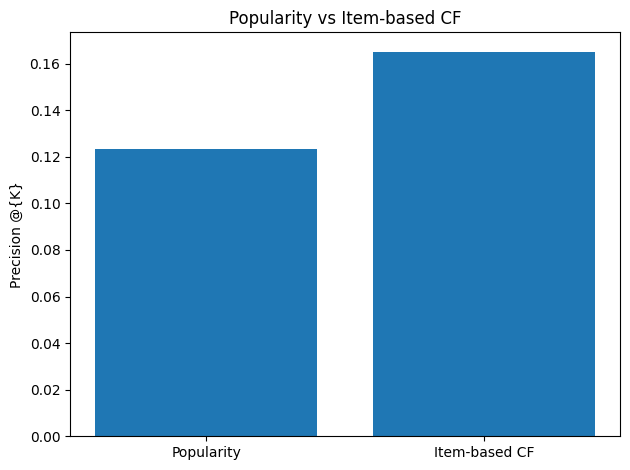

In [13]:
model_names = list(results.keys())
precision_values = [results[m][0] for m in model_names]
plt.bar(model_names, precision_values)
plt.ylabel("Precision @{K}")
plt.title("Popularity vs Item-based CF")
plt.tight_layout()
plt.savefig("comparison_chart.png")
plt.show()

In [14]:
movie_lookup = movies.set_index("movieId")

def recommend(user_id, n=10):
    i = int(np.where(user_ids == user_id)[0][0])
    top_idx = np.argsort(cf_scores[i])[::-1][:n]
    return movie_lookup.loc[movie_ids[top_idx], ["title", "genres"]]

def liked_by(user_id, n=5):
    u = train[(train["userId"] == user_id) & (train["rating"] >= 4.5)]
    return movie_lookup.loc[u["movieId"].head(n), ["title", "genres"]]

print("User 1 rated highly:")
print(liked_by(1))
print("\nRecommended for user 1:")
print(recommend(1))

User 1 rated highly:
                                title  \
movieId                                 
2502              Office Space (1999)   
2761           Iron Giant, The (1999)   
2948     From Russia with Love (1963)   
2993               Thunderball (1965)   
2947                Goldfinger (1964)   

                                            genres  
movieId                                             
2502                                  Comedy|Crime  
2761     Adventure|Animation|Children|Drama|Sci-Fi  
2948                     Action|Adventure|Thriller  
2993                     Action|Adventure|Thriller  
2947                     Action|Adventure|Thriller  

Recommended for user 1:
                                               title  \
movieId                                                
2918                 Ferris Bueller's Day Off (1986)   
1089                           Reservoir Dogs (1992)   
2115     Indiana Jones and the Temple of Doom (1984)   
1527           

## Conclusion

**Goal:** Recommend movies to users based on their past ratings, and check whether item-based collaborative filtering (CF) beats a simple popularity baseline.

**Data:** MovieLens ml-latest-small (GroupLens). After keeping only movies with at least 20 ratings, **67,898** ratings remained from **610** users across **1,297** movies. Ratings were split randomly 80/20 into 54,318 training and 13,580 test ratings (random_state = 42).

**Methods:**
- **Popularity baseline:** recommends the movies most often rated 4 or higher in the training set, excluding movies the user has already rated.
- **Item-based CF:** computes cosine similarity between movies from the user-movie rating matrix; each unseen movie is scored by its similarity to the movies the user has rated.
- **Evaluation:** a movie counts as "liked" if its test rating is 4 or higher. For each of the 586 users with at least one liked movie in the test set, the top 10 recommendations were compared against those movies.

**Results:**

| Model | Precision@10 | Recall@10 |
|---|---|---|
| Popularity | 0.1232 | 0.1204 |
| Item-based CF | 0.1652 | 0.1916 |

**Finding:** Item-based CF outperformed the popularity baseline on both Precision@10 (0.165 vs 0.123) and Recall@10 (0.192 vs 0.120) in this split. Absolute values are modest because only 20% of ratings are held out as the test set, so many reasonable recommendations are counted as misses.

**Sanity check:** For user 1, who rated action/adventure films such as *From Russia with Love* and *Goldfinger* highly, the CF model recommended titles such as *Indiana Jones and the Temple of Doom*, *The Fifth Element* and *Total Recall*, which are broadly similar in genre. This is a single example, not evidence of overall quality.

**Limitations:**
- Offline evaluation on one random split; there is no real-user testing and no confidence intervals or significance test, so the size of the gap is only indicative.
- Only movies with at least 20 ratings (1,297 of about 9,700) were used, so results do not apply to less-rated movies.
- Unrated movies are treated as zeros in the similarity calculation, which is a simplification, and raw scores can favour movies rated by many users.
- No hyperparameter tuning or comparison with other methods (e.g. matrix factorization).
- Cold start: the model cannot recommend for new users or new movies.
- MovieLens ml-latest-small is a development dataset and is not intended for reporting research results.